In [33]:
import xarray as xr
import matplotlib.pyplot as plt
import functions as fns
import numpy as np

In [34]:
case = 'carma_SDPSul_CS_optics_test_cf30,50,70,90_bin1,10000nm'
ds = xr.open_dataset(f'/home/n02/n02/hqmp0145/CARMA/run/carma/{case}.nc', decode_times=False)

In [35]:
ds = ds.sortby("wave")

variable_label = {
    'PRSUL': 'Pure sulphate', 
                #   'ALSUL_fixed_wet': 'Al-Sul wet - fixed core', 
                  'ALSUL_fixed_dry': 'Al-Sul dry - fixed core',
                  # 'ALSUL_coreshell_cf90_wet': 'Al-Sul wet - core/shell cf90', 
                  'ALSUL_coreshell_cf90_dry': 'Al-Sul dry - core/shell cf90',
                  # 'ALSUL_coreshell_cf70_wet': 'Al-Sul wet - core/shell cf70', 
                  'ALSUL_coreshell_cf70_dry': 'Al-Sul dry - core/shell cf70',
                  # 'ALSUL_coreshell_cf50_wet': 'Al-Sul wet - core/shell cf50', 
                  'ALSUL_coreshell_cf50_dry': 'Al-Sul dry - core/shell cf50',
                  # 'ALSUL_coreshell_cf30_wet': 'Al-Sul wet - core/shell cf30', 
                  'ALSUL_coreshell_cf30_dry': 'Al-Sul dry - core/shell cf30',
                  }

plot_dir = '/home/n02/n02/hqmp0145/CARMA/analysis/plots'

In [36]:
target_radii = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3] # target radii for 1, 10, 100, 1000, 10,000nm particles 

def find_bin_index(ds, target_radius, variable):
    radii = ds[f"{variable}_r"]
    index = abs(np.log10(radii) - np.log10(target_radius)).argmin(dim="bin") 
    return int(index) + 1, float(radii.isel(bin=index))

radii_dict_dry = {}
for r in target_radii:
    idx, rad = find_bin_index(ds, r, "ALSUL_fixed_dry")
    radii_dict_dry[r] = idx
    print(f"target {r:.0e} cm -> bin {idx}, radius {rad:.3e} cm")

radii_dict_dry

target 1e-07 cm -> bin 1, radius 1.000e-07 cm
target 1e-06 cm -> bin 10, radius 1.000e-06 cm
target 1e-05 cm -> bin 19, radius 1.000e-05 cm
target 1e-04 cm -> bin 28, radius 1.000e-04 cm
target 1e-03 cm -> bin 37, radius 1.000e-03 cm


{1e-07: 1, 1e-06: 10, 1e-05: 19, 0.0001: 28, 0.001: 37}

In [37]:
def plot_optical_property(property_name, ylabel=None, yscale='linear', save=False):
    if len(target_radii) > 5:
        raise ValueError('This layout supports at most five target radii.')

    fig, axes = plt.subplots(2, 3, figsize=(12, 8), sharex=True, sharey=True)
    axes = axes.flatten()

    # Assign one color to each dry/wet variable pair.
    color_cycle = plt.rcParams['axes.prop_cycle'].by_key()['color']
    variable_groups = {}
    for variable in variable_label:
        dry_variable = variable.replace('wet', 'dry')
        variable_groups.setdefault(dry_variable, []).append(variable)
    color_by_group = {
        group: color_cycle[index % len(color_cycle)]
        for index, group in enumerate(variable_groups)
    }

    for ax, target_radius in zip(axes, target_radii):
        for variable, label in variable_label.items():
            bin_number, _ = find_bin_index(ds, target_radius, variable)
            ds[f'{variable}_{property_name}'].isel(bin=bin_number - 1).plot(
                ax=ax,
                xscale='log',
                color=color_by_group[variable.replace('wet', 'dry')],
                linestyle='--' if 'wet' in variable else '-',
                label=label,
            )

        ax.set_title(f'Radius = {target_radius * 1e7:.0f} nm')
        ax.set_yscale(yscale)
        ax.grid()
        fns.add_SW_LW_plot_areas(ax)

    # Use the sixth subplot for the shared legend.
    legend_ax = axes[5]
    legend_ax.axis('off')
    handles, labels = axes[0].get_legend_handles_labels()
    legend_ax.legend(handles, labels, loc='center')

    # Show y-labels only on the left edge and x-labels only on the bottom edge.
    for ax in axes[:5]:
        ax.set_ylabel('' if ax not in (axes[0], axes[3]) else (ylabel or property_name))
        ax.set_xlabel('' if ax not in (axes[3], axes[4]) else 'Wavelength (cm)')

    plt.tight_layout()
    if save==True:
        plt.savefig(f'{plot_dir}/{case}_{property_name}.png', bbox_inches='tight')
    return fig, axes

### Extinction efficiency

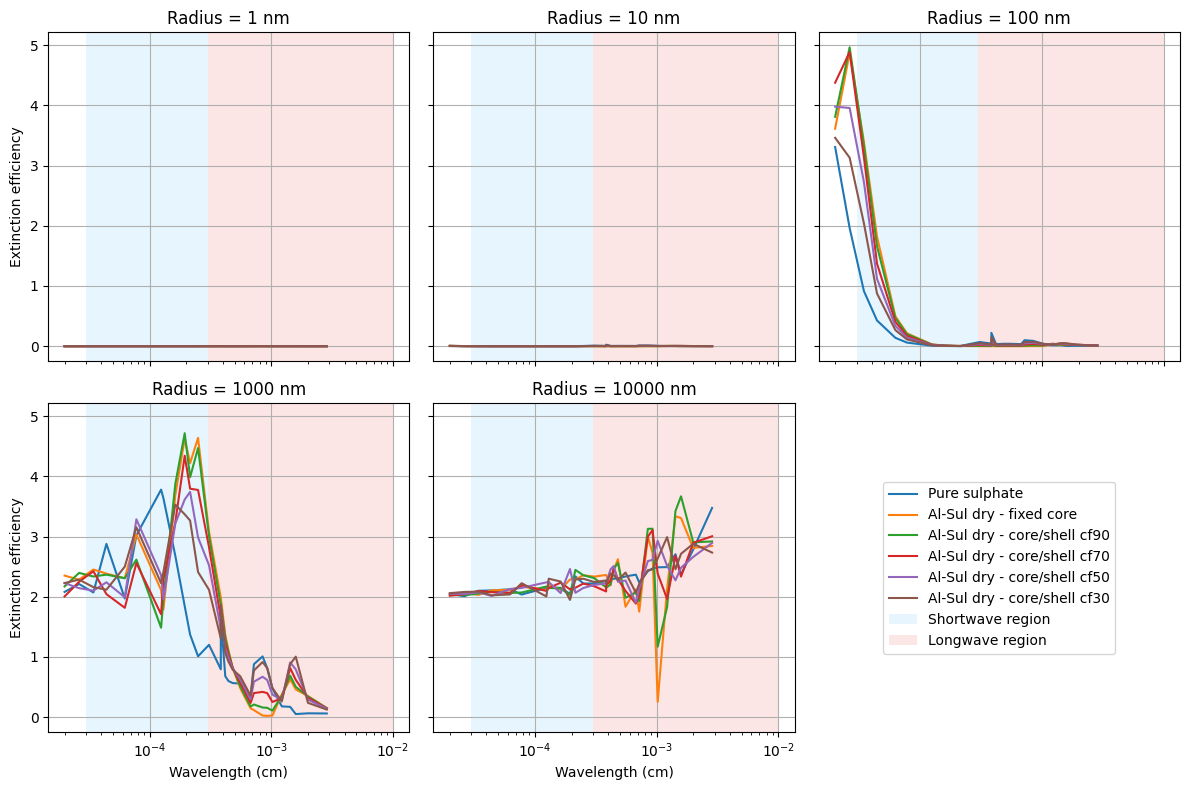

In [38]:
fig, axes = plot_optical_property('qext', ylabel='Extinction efficiency', yscale='linear', save=True)
plt.show()

### Single scattering albedo

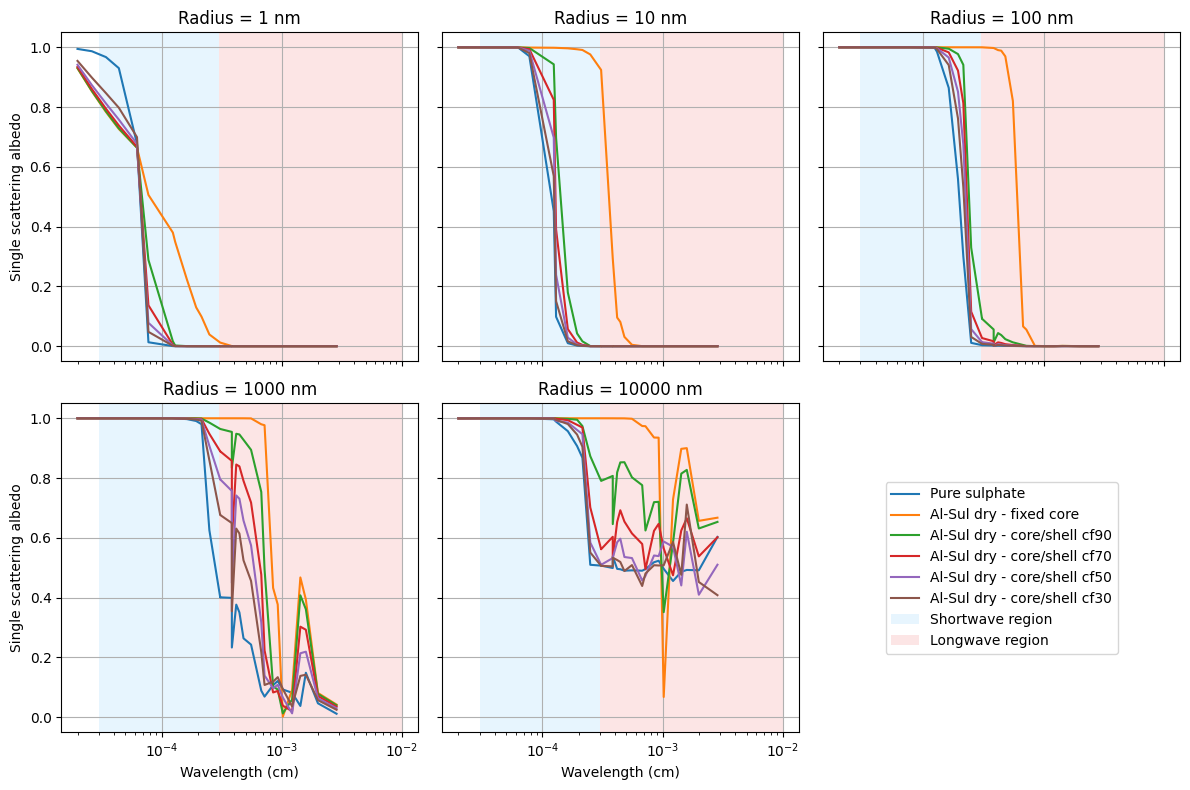

In [39]:
fig, axes = plot_optical_property('ssa', ylabel='Single scattering albedo', yscale='linear', save=True)
plt.show()

### Asymmetry factor

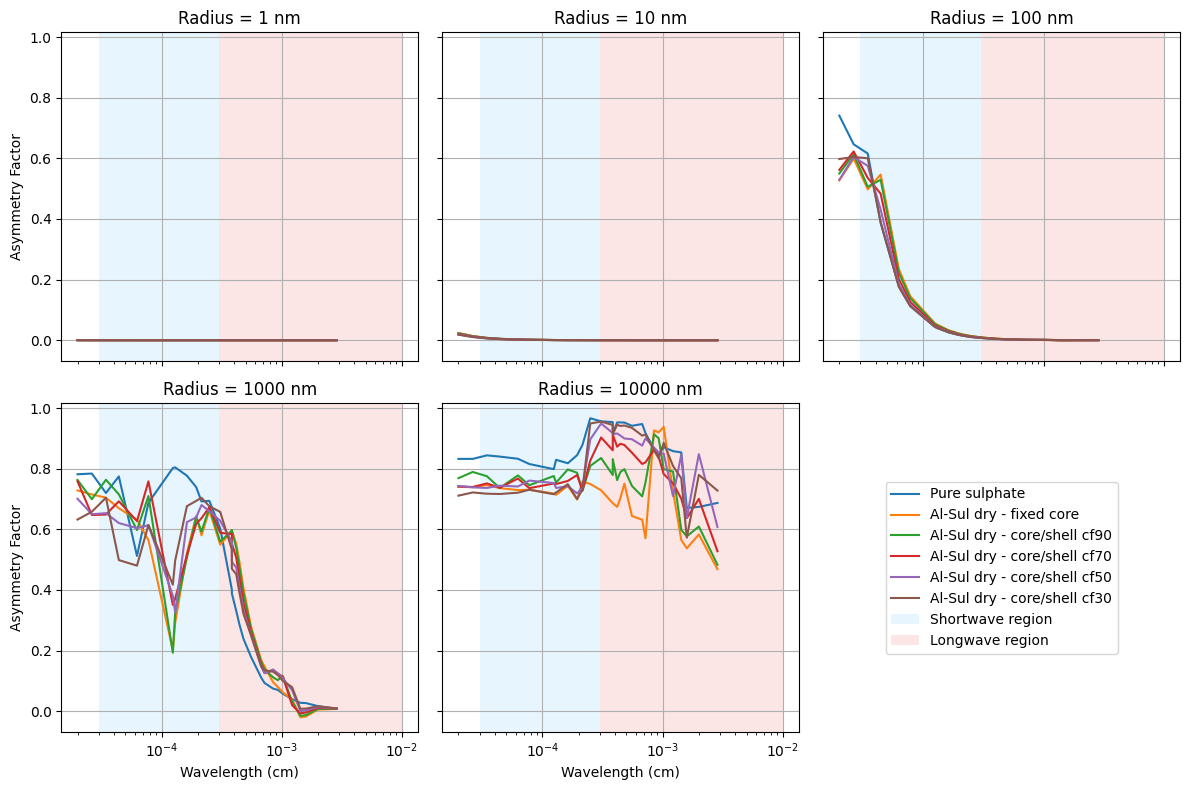

In [42]:
fig, axes = plot_optical_property('asy', ylabel='Asymmetry Factor', yscale='linear', save=True)
plt.show()